In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/13H1VTAZ42.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/G0DWU2GK1L.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/CVPHC0DT1P.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/90XJFQDL7G.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/3V8LZ56MOW.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/Y9EUV6TNP2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/K76P42J0GK.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/ZSS7THB1UM.jpg
/kaggle/input/comp

In [2]:

# ============================================================
# SURFACEGUARD AI — MASTER SETUP & VERIFICATION CELL
# Recreates variables and checks the pipeline without training
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

# Cell 1: setup and load

In [3]:

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset paths
ROOT = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")

CSV = ROOT / "train.csv"
TRAIN_DIR = ROOT / "train"
TEST_DIR = ROOT / "test"

H, W = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Decode column-major RLE into a binary mask
def rle_decode(rle, h=H, w=W):
    mask = np.zeros(h * w, dtype=np.uint8)

    if isinstance(rle, str) and rle.strip():
        values = np.asarray(rle.split(), dtype=np.int64)
        starts = values[0::2] - 1
        lengths = values[1::2]

        for start, length in zip(starts, lengths):
            mask[start:start + length] = 1

    return mask.reshape((w, h)).T

# Encode a binary mask using column-major RLE
def rle_encode(mask):
    mask = np.asarray(mask, dtype=np.uint8)
    pixels = mask.T.flatten()

    padded = np.concatenate(([0], pixels, [0]))
    changes = np.where(padded[1:] != padded[:-1])[0] + 1
    changes[1::2] -= changes[::2]

    return " ".join(map(str, changes))

# Load training annotations
assert CSV.exists(), f"Training CSV not found: {CSV}"

df = pd.read_csv(CSV)

# Empty or missing RLE means no defect
df["has"] = (
    df["mask_rle"].fillna("").astype(str).str.strip().ne("")
).astype(int)

# Count images on disk
train_images = list(TRAIN_DIR.glob("*.jpg"))
test_images = list(TEST_DIR.glob("*.jpg"))

print("Training CSV shape:", df.shape)
print("Unique training images:", df["image_id"].nunique())
print("Training images on disk:", len(train_images))
print("Test images on disk:", len(test_images))
print("\nDefect annotation counts:")
print(df.groupby("defect_type")["has"].sum())

# Verify RLE encode/decode round-trip
test_mask = np.zeros((H, W), dtype=np.uint8)
test_mask[10:20, 30:50] = 1

encoded = rle_encode(test_mask)
decoded = rle_decode(encoded)

assert np.array_equal(test_mask, decoded), "RLE round-trip failed!"
print("\nRLE round-trip test passed.")


Training CSV shape: (45572, 6)
Unique training images: 11393
Training images on disk: 11393
Test images on disk: 3000

Defect annotation counts:
defect_type
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
Name: has, dtype: int64

RLE round-trip test passed.


# Cell 2: image-level stats

In [4]:
wide = df.pivot(index="image_id", columns="defect_type", values="has")[CLASSES]
n_def = wide.sum(1)
print("Defects per image:\n", n_def.value_counts().sort_index())
print("\nImages with NO defect: %.1f%%" % (100 * (n_def == 0).mean()))
print("\nCo-occurrence (counts):\n", wide.T.dot(wide))
print("\nCombination patterns (top 10):\n", wide.astype(str).agg("".join, axis=1).value_counts().head(10))

# per-class mask area (% of image) and number of connected regions
ne = df.dropna(subset=["mask_rle"]).copy()
ne["area"] = ne.mask_rle.apply(lambda s: sum(map(int, s.split()[1::2])))
ne["area_pct"] = 100 * ne.area / (H * W)
ne["n_runs"] = ne.mask_rle.apply(lambda s: len(s.split()) // 2)
print("\n", ne.groupby("defect_type")[["area_pct", "n_runs"]].describe().T.round(2))

Defects per image:
 0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64

Images with NO defect: 48.4%

Co-occurrence (counts):
 defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707

Combination patterns (top 10):
 0000    5516
0010    3105
0001     822
1000     601
0011     598
1010     215
0100     151
1001     136
1011      87
0110      67
Name: count, dtype: int64

 defect_type     defect_a  defect_b  defect_c  defect_d
area_pct count   1081.00    313.00   4100.00   1707.00
         mean       0.73      0.67      5.43      6.98
         std        0.74      0.40      8.43      6.41
         min        0.04      0.09      0.03      0.07
         25%        0.25      0.39      1.04      2.49
         50%        0.46 

# Cell 3: overlays (look at the defects)

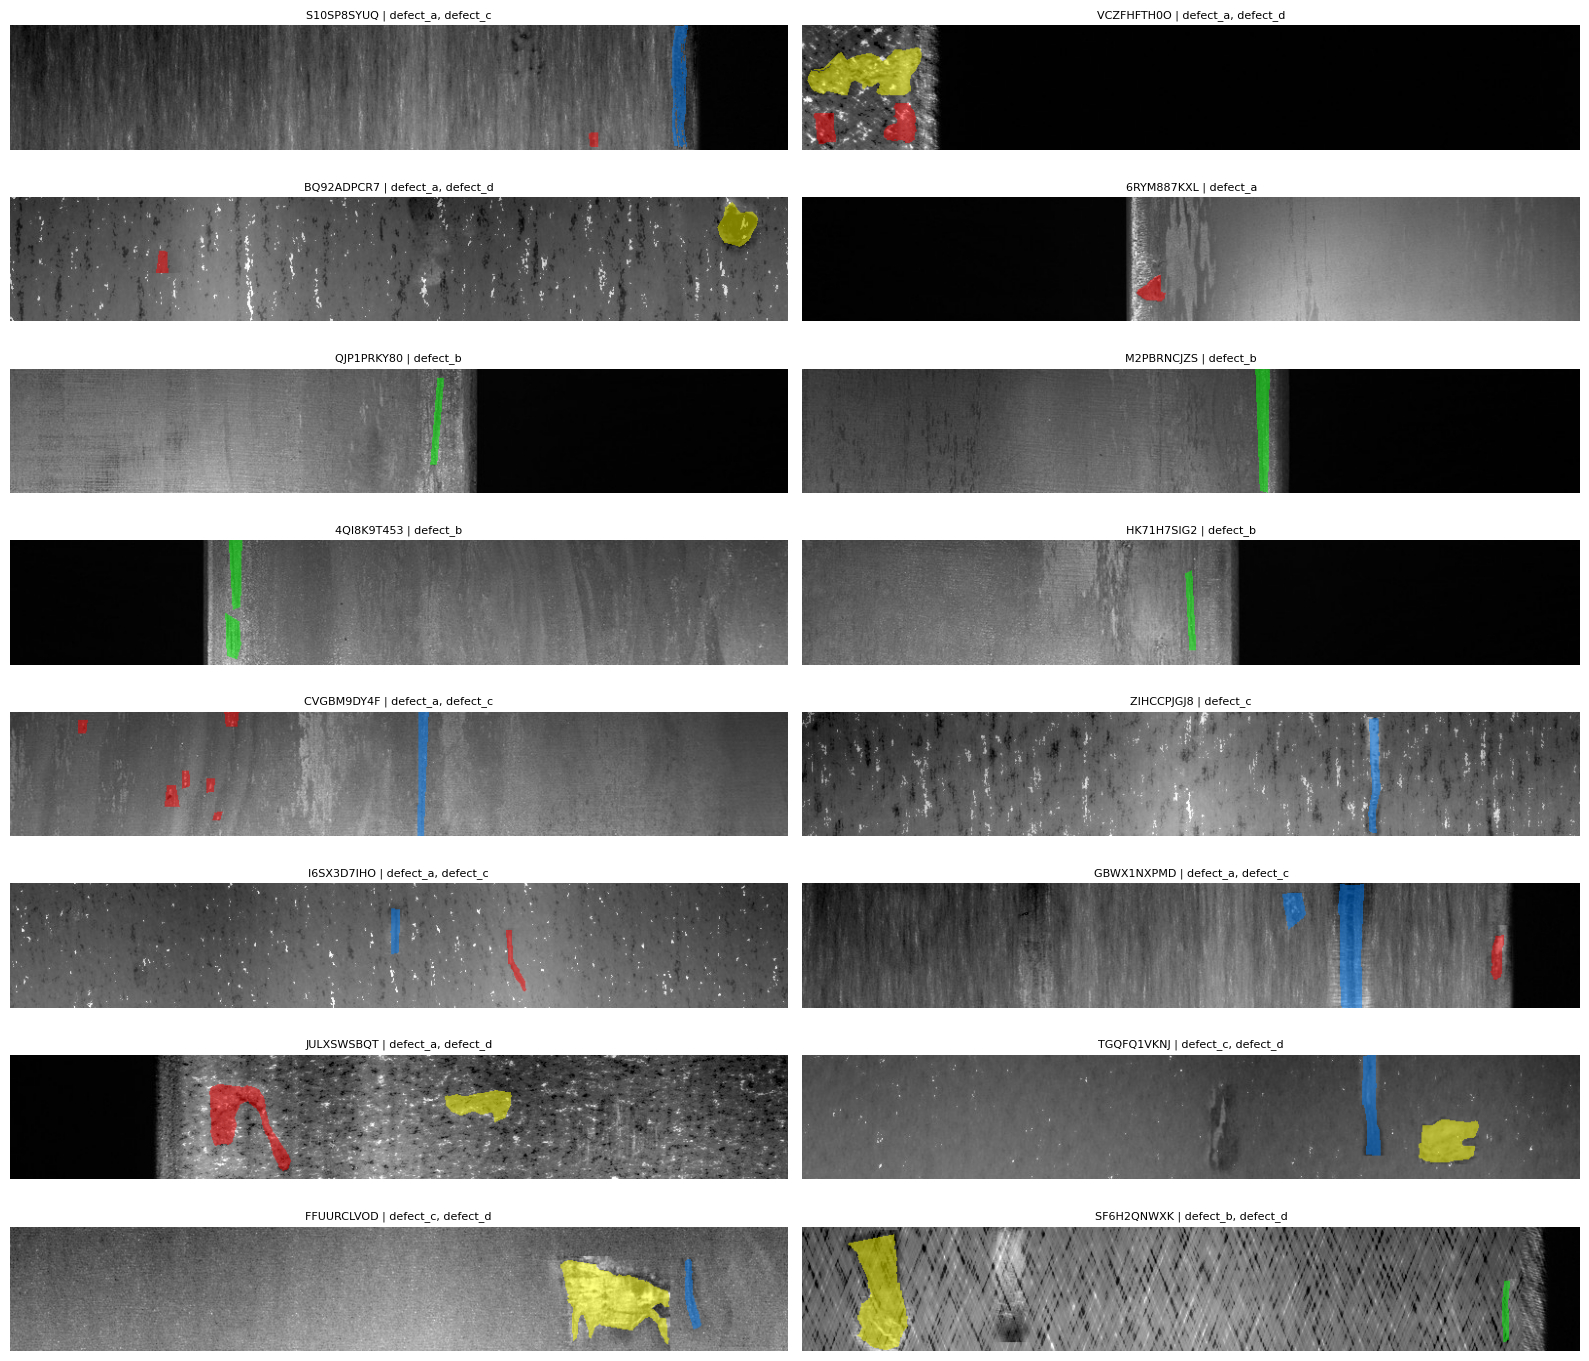

Saved: /kaggle/working/defect_visualization.png
File exists: True
File size (MB): 3.64


In [5]:
# Overlay colors in RGB order: red, green, blue-orange, yellow
colors = {
    "defect_a": (255, 0, 0),
    "defect_b": (0, 255, 0),
    "defect_c": (0, 128, 255),
    "defect_d": (255, 255, 0),
}

def show(image_id, ax):
    image_path = TRAIN_DIR / f"{image_id}.jpg"

    if not image_path.exists():
        ax.set_title(f"Image not found: {image_id}", fontsize=8)
        ax.axis("off")
        return

    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        ax.set_title(f"Could not read: {image_id}", fontsize=8)
        ax.axis("off")
        return

    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

    rows = df[
        (df["image_id"] == image_id) &
        (df["has"] == 1)
    ]

    for _, row in rows.iterrows():
        category = row["defect_type"]

        if category not in colors:
            continue

        mask = rle_decode(
            row["mask_rle"],
            h=img.shape[0],
            w=img.shape[1]
        ).astype(bool)

        if mask.shape != rgb.shape[:2]:
            raise ValueError(
                f"Mask shape {mask.shape} does not match "
                f"image shape {rgb.shape[:2]} for {image_id}"
            )

        color = np.array(colors[category], dtype=np.float32)
        rgb[mask] = (
            0.5 * rgb[mask].astype(np.float32) +
            0.5 * color
        ).astype(np.uint8)

    ax.imshow(rgb)
    ax.axis("off")
    ax.set_title(
        f"{image_id} | {', '.join(rows['defect_type'].tolist())}",
        fontsize=8
    )


# Display four randomly selected positive examples per category
rng = np.random.default_rng(0)

fig, axes = plt.subplots(8, 2, figsize=(16, 14))

for ax, category in zip(
    axes.flat,
    [category for category in CLASSES for _ in range(4)]
):
    ids = df.loc[
        (df["defect_type"] == category) & (df["has"] == 1),
        "image_id"
    ].unique()

    if len(ids) == 0:
        ax.set_title(f"No positive examples: {category}", fontsize=8)
        ax.axis("off")
        continue

    image_id = rng.choice(ids)
    show(image_id, ax)

plt.tight_layout()
plt.show()

from IPython.display import display
from pathlib import Path

output_path = Path("/kaggle/working/defect_visualization.png")

fig.tight_layout()
fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print("Saved:", output_path)
print("File exists:", output_path.exists())
print("File size (MB):", round(output_path.stat().st_size / (1024**2), 2))

# Cell 4: image properties and RLE round-trip check

In [6]:
# 1) RLE round-trip on 500 random masks
samp = ne.sample(500, random_state=0)
print("round-trip OK:", all(rle_encode(rle_decode(s)) == s.strip() for s in samp.mask_rle))

# 2) pixel stats on 300 random train images (decides normalisation)
ids = rng.choice(df.image_id.unique(), 300, replace=False)
imgs = [cv2.imread(str(TRAIN_DIR / f"{i}.jpg"), 0) for i in ids]
print("shapes:", {i.shape for i in imgs})
a = np.stack(imgs) / 255.0
print("mean %.3f  std %.3f  | per-image mean range %.2f-%.2f" % (a.mean(), a.std(), a.mean((1,2)).min(), a.mean((1,2)).max()))

round-trip OK: True
shapes: {(128, 800)}
mean 0.347  std 0.189  | per-image mean range 0.02-0.63


# Cell 5: folds (stratified on the defect pattern)

In [7]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS, SEED = 5, 42
meta = wide.copy()
meta["pattern"] = meta[CLASSES].astype(str).agg("".join, axis=1)
vc = meta.pattern.value_counts()
meta["strat"] = meta.pattern.where(meta.pattern.map(vc) >= N_FOLDS, "rare")
meta = meta.reset_index()                       # columns: image_id, defect_a..d, pattern, strat
meta["fold"] = -1
for f, (_, va) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(meta, meta.strat)):
    meta.loc[va, "fold"] = f
print(meta.fold.value_counts().sort_index())
print(meta.groupby("fold")[CLASSES].sum())       # each class should be spread evenly

# image_id -> list of 4 RLE strings ("" if empty)
rle_map = {iid: [g.set_index("defect_type").mask_rle.get(c) for c in CLASSES]
           for iid, g in df.groupby("image_id")}
rle_map = {k: [v if isinstance(v, str) else "" for v in vs] for k, vs in rle_map.items()}

fold
0    2279
1    2279
2    2279
3    2278
4    2278
Name: count, dtype: int64
defect_type  defect_a  defect_b  defect_c  defect_d
fold                                               
0                 216        62       821       341
1                 217        64       819       341
2                 217        63       820       341
3                 216        62       820       342
4                 215        62       820       342


# Cell 6: dataset and augmentations

In [8]:
import torch, albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader

MEAN, STD = 0.3347, 0.189     # <- replace with the real values from Cell 4

def get_train_aug():
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomBrightnessContrast(0.15, 0.15, p=0.4),
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=5,
                           border_mode=cv2.BORDER_CONSTANT, p=0.3),
        A.Normalize(mean=MEAN, std=STD, max_pixel_value=255.0),
        ToTensorV2(),
    ])

def get_valid_aug():
    return A.Compose([A.Normalize(mean=MEAN, std=STD, max_pixel_value=255.0), ToTensorV2()])

class SteelDS(Dataset):
    def __init__(self, ids, img_dir, aug, has_mask=True, in_ch=1):
        self.ids, self.dir, self.aug, self.has_mask, self.in_ch = list(ids), img_dir, aug, has_mask, in_ch
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        img = cv2.imread(str(self.dir / f"{iid}.jpg"), 0)
        if self.has_mask:
            masks = [rle_decode(r) for r in rle_map[iid]]
            out = self.aug(image=img, masks=masks)
            x = out["image"]                                   # (1,H,W)
            y = torch.stack([m.float() for m in out["masks"]]) # (4,H,W)
        else:
            x = self.aug(image=img)["image"]; y = torch.zeros(4, H, W)
        if self.in_ch == 3: x = x.repeat(3, 1, 1)              # for pretrained encoders
        return x.float(), y, iid

def make_loaders(fold, bs=16, in_ch=1, workers=2):
    tr = meta[meta.fold != fold].image_id; va = meta[meta.fold == fold].image_id
    return (DataLoader(SteelDS(tr, TRAIN_DIR, get_train_aug(), True, in_ch), bs, shuffle=True, num_workers=workers, drop_last=True),
            DataLoader(SteelDS(va, TRAIN_DIR, get_valid_aug(), True, in_ch), bs, shuffle=False, num_workers=workers))

# Cell 7: sanity check

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


x torch.Size([16, 1, 128, 800]) torch.float32 -1.7708992958068848 3.5201058387756348
y torch.Size([16, 4, 128, 800]) positive pixel % per class: [0.04290771484375, 0.0, 0.880615234375, 0.9412232041358948]
train batches: 569 | valid batches: 143


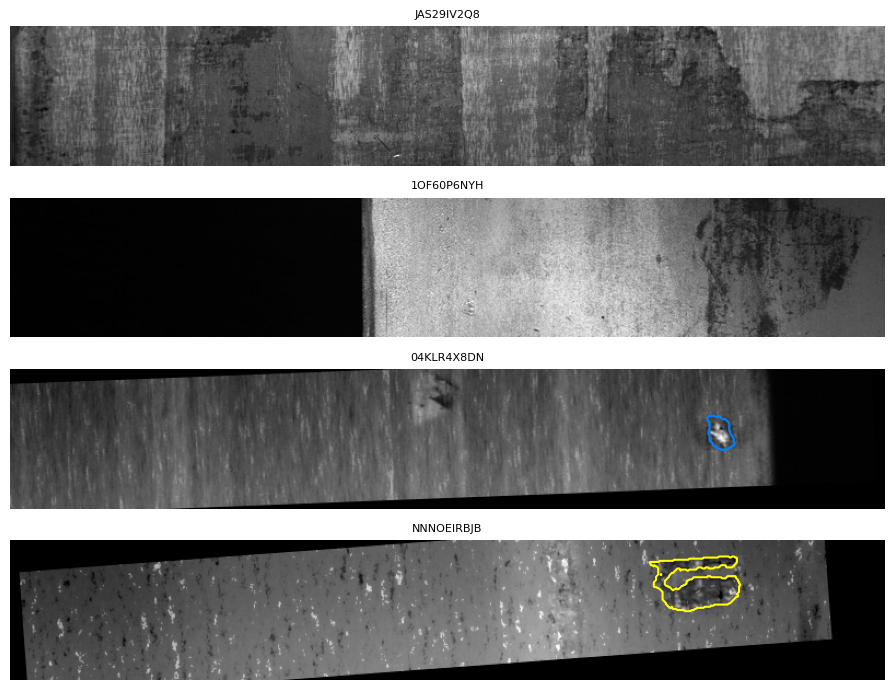

Saved: /kaggle/working/defect_visualization2.png
File exists: True
File size (MB): 1.02


In [9]:
tl, vl = make_loaders(fold=0, in_ch=1)
x, y, ids = next(iter(tl))
print("x", x.shape, x.dtype, float(x.min()), float(x.max()))
print("y", y.shape, "positive pixel % per class:", (y.mean((0, 2, 3)) * 100).tolist())
print("train batches:", len(tl), "| valid batches:", len(vl))

# visual check that aug and masks stay aligned
fig, ax = plt.subplots(4, 1, figsize=(14, 7))
for k in range(4):
    im = x[k, 0].numpy() * STD + MEAN
    ax[k].imshow(im, cmap="gray")
    for c in range(4):
        ax[k].contour(y[k, c].numpy(), levels=[0.5], colors=[np.array(list(colors.values())[c]) / 255])
    ax[k].axis("off"); ax[k].set_title(ids[k], fontsize=8)
plt.tight_layout(); plt.show()

from IPython.display import display
from pathlib import Path

output_path = Path("/kaggle/working/defect_visualization2.png")

fig.tight_layout()
fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

print("Saved:", output_path)
print("File exists:", output_path.exists())
print("File size (MB):", round(output_path.stat().st_size / (1024**2), 2))

# Cell 8: metric, loss, and a sanity test

In [10]:
MEAN, STD = 0.347, 0.189    

class Scorer:
    """Accumulates the competition score batch by batch (no giant arrays in memory).
    Assumed definitions (calibrate against your Kaggle score):
      fg_dice  = mean Dice over (image,class) pairs where GT is non-empty (0 if pred empty)
      fp_score = 1 - mean(predicted_area / image_area) over pairs where GT is empty
      empty_acc= fraction of GT-empty pairs where the prediction is also empty
    """
    def __init__(self, thr=0.5, min_area=0):
        self.thr, self.min_area = thr, min_area
        self.d, self.fp, self.em = [], [], []          # lists of (B,4) tensors

    @torch.no_grad()
    def update(self, logits, y):
        p = (torch.sigmoid(logits) > self.thr).float()
        area = p.sum((2, 3))
        p = p * (area >= self.min_area).float()[..., None, None]   # drop tiny predictions
        area = p.sum((2, 3)); g = y.sum((2, 3)); inter = (p * y).sum((2, 3))
        dice = 2 * inter / (area + g + 1e-9)
        pos = g > 0
        self.d.append(torch.where(pos, dice, torch.full_like(dice, float("nan"))).cpu())
        self.fp.append(torch.where(~pos, area / (H * W), torch.full_like(dice, float("nan"))).cpu())
        self.em.append(torch.where(~pos, (area == 0).float(), torch.full_like(dice, float("nan"))).cpu())

    def compute(self):
        d, fp, em = [torch.cat(x) for x in (self.d, self.fp, self.em)]
        fg, fp_area, ea = d.nanmean().item(), 1 - fp.nanmean().item(), em.nanmean().item()
        fps = ea
        out = {"score": 0.70 * fg + 0.20 * fps + 0.10 * ea, "fg_dice": fg, "fp_score": fps,
               "fp_area": fp_area, "empty_acc": ea}
        for i, c in enumerate(CLASSES):
            out[f"dice_{c}"] = d[:, i].nanmean().item()
        return out

import torch.nn as nn
class BCEDiceLoss(nn.Module):
    """BCE on all pixels + Dice only on (image,class) pairs that actually contain a defect."""
    def __init__(self, w_bce=0.5, w_dice=0.5):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(); self.wb, self.wd = w_bce, w_dice
    def forward(self, logits, y):
        p = torch.sigmoid(logits)
        g = y.sum((2, 3)); pos = (g > 0).float()
        inter = (p * y).sum((2, 3)); den = p.sum((2, 3)) + g
        dice = 1 - (2 * inter + 1) / (den + 1)
        dl = (dice * pos).sum() / pos.sum().clamp(min=1)
        return self.wb * self.bce(logits, y) + self.wd * dl

xb, yb, _ = next(iter(tl))
perfect = (y * 2 - 1) * 10 
empty   = torch.full_like(y, -10.0)
l_empty = BCEDiceLoss()(torch.full_like(yb, -10.0), yb).item()
print("all-empty loss (must be > 0.4):", round(l_empty, 4))
assert l_empty > 0.4, "old loss still active!"

all-empty loss (must be > 0.4): 0.5363


# Cell 9: fixed loss and the scratch U-Net

In [11]:
class BCEDiceLoss(nn.Module):
    """BCE on all pixels + Dice only on (image,class) pairs that actually contain a defect."""
    def __init__(self, w_bce=0.5, w_dice=0.5):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(); self.wb, self.wd = w_bce, w_dice
    def forward(self, logits, y):
        p = torch.sigmoid(logits)
        g = y.sum((2, 3)); pos = (g > 0).float()
        inter = (p * y).sum((2, 3)); den = p.sum((2, 3)) + g
        dice = 1 - (2 * inter + 1) / (den + 1)
        dl = (dice * pos).sum() / pos.sum().clamp(min=1)
        return self.wb * self.bce(logits, y) + self.wd * dl

# re-check: perfect should now be ~0.0x, empty clearly higher
print("loss perfect %.4f | loss empty %.4f" % (BCEDiceLoss()(perfect, y).item(), BCEDiceLoss()(empty, y).item()))

def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class ScratchUNet(nn.Module):
    def __init__(self, in_ch=1, n_cls=4, f=32):
        super().__init__()
        ch = [f, f * 2, f * 4, f * 8, f * 16]
        self.enc = nn.ModuleList([block(in_ch, ch[0])] + [block(ch[i], ch[i + 1]) for i in range(4)])
        self.pool = nn.MaxPool2d(2)
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, 2) for i in range(4)])
        self.dec = nn.ModuleList([block(ch[i] * 2, ch[i]) for i in range(4)])
        self.head = nn.Conv2d(ch[0], n_cls, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else self.pool(x)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), skips[i]], 1))
        return self.head(x)

m = ScratchUNet()
print("params (M):", sum(p.numel() for p in m.parameters()) / 1e6, "| out:", m(torch.zeros(2, 1, H, W)).shape)

loss perfect 0.0009 | loss empty 0.5229
params (M): 7.762564 | out: torch.Size([2, 4, 128, 800])


# Cell 10: training loop with WandB

In [12]:
import os, wandb
try:
    from kaggle_secrets import UserSecretsClient
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
except Exception:
    wandb.login()          # falls back to the normal prompt (Colab or local)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [13]:
torch.backends.cudnn.benchmark = True
import wandb, time
device = "cuda" if torch.cuda.is_available() else "cpu"
# wandb.login()   # run once, paste your API key

def evaluate(model, loader, crit, thr=0.5, min_area=0):
    model.eval(); sc = Scorer(thr, min_area); tot = 0
    with torch.no_grad(), torch.autocast(device, enabled=device == "cuda"):
        for x, y, _ in loader:
            x, y = x.to(device), y.to(device)
            lg = model(x); tot += crit(lg.float(), y).item(); sc.update(lg.float(), y)
    r = sc.compute(); r["val_loss"] = tot / len(loader); return r

def run(model, name, fold=0, epochs=30, lr=3e-4, bs=16, in_ch=1, wd=1e-4,workers=4, project="surface-anomaly-seg"):
    tl, vl = make_loaders(fold, bs, in_ch, workers)
    model = model.to(device); crit = BCEDiceLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tl))
    scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
    wandb.init(project=project, name=name, config=dict(model=name, fold=fold, epochs=epochs, lr=lr, bs=bs, wd=wd,
               params_M=sum(p.numel() for p in model.parameters()) / 1e6), reinit=True)
    best = 0
    for ep in range(epochs):
        model.train(); t0 = time.time(); tot = 0
        for x, y, _ in tl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device, enabled=device == "cuda"):
                loss = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        r = evaluate(model, vl, crit, min_area=100)
        wandb.log({"epoch": ep, "train_loss": tot / len(tl), "lr": sched.get_last_lr()[0], **r})
        print(f"ep{ep:02d} loss {tot/len(tl):.4f} | val {r['val_loss']:.4f} score {r['score']:.4f} "
              f"dice {r['fg_dice']:.3f} fp {r['fp_score']:.3f} emp {r['empty_acc']:.3f} | {time.time()-t0:.0f}s")
        if r["score"] > best:
            best = r["score"]; torch.save(model.state_dict(), f"{name}_fold{fold}.pt")
    wandb.summary["best_score"] = best; wandb.finish(); return best

# Cell 11: smoke test first (2 epochs only)

run(ScratchUNet(in_ch=1, f=32), "scratch_unet_smoke", fold=0, epochs=2, lr=1e-3, bs=16)

# Cell 12: full Model 1 run

In [14]:
run(ScratchUNet(in_ch=1, f=32), "scratch_unet_f32", fold=0, epochs=20, lr=1e-3, bs=16, workers=4)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_22/4051175151.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: setting up run i2yuqbb8
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261027_165247-i2yuqbb8
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run scratch_unet_f32
wandb: ⭐️ View project at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg
wandb: 🚀 View run at https://wandb.ai/24f2008353-indian-institute-of-t

ep00 loss 0.6898 | val 0.6244 score 0.4002 dice 0.323 fp 0.580 emp 0.580 | 197s
ep01 loss 0.5414 | val 0.4450 score 0.4498 dice 0.367 fp 0.643 emp 0.643 | 163s
ep02 loss 0.3944 | val 0.3549 score 0.4306 dice 0.397 fp 0.509 emp 0.509 | 163s
ep03 loss 0.3451 | val 0.3445 score 0.4091 dice 0.394 fp 0.444 emp 0.444 | 163s
ep04 loss 0.3253 | val 0.3149 score 0.4006 dice 0.438 fp 0.314 emp 0.314 | 163s
ep05 loss 0.3140 | val 0.3160 score 0.3988 dice 0.453 fp 0.271 emp 0.271 | 163s
ep06 loss 0.3027 | val 0.3076 score 0.4250 dice 0.474 fp 0.311 emp 0.311 | 163s
ep07 loss 0.2945 | val 0.2826 score 0.4546 dice 0.492 fp 0.367 emp 0.367 | 163s
ep08 loss 0.2835 | val 0.2761 score 0.4953 dice 0.495 fp 0.496 emp 0.496 | 163s
ep09 loss 0.2786 | val 0.2650 score 0.4881 dice 0.518 fp 0.417 emp 0.417 | 163s
ep10 loss 0.2734 | val 0.2658 score 0.4983 dice 0.528 fp 0.429 emp 0.429 | 163s
ep11 loss 0.2635 | val 0.2569 score 0.5271 dice 0.531 fp 0.518 emp 0.518 | 163s
ep12 loss 0.2566 | val 0.2537 score 0.52

wandb: updating run metadata


ep19 loss 0.2227 | val 0.2224 score 0.5795 dice 0.593 fp 0.547 emp 0.547 | 163s


wandb: uploading history steps 19-19, summary, console lines 19-19
wandb: 
wandb: Run history:
wandb: dice_defect_a ▁▁▅▂▆▆▆▇▆▇▇▇▇███████
wandb: dice_defect_b ▁▁▁▃▄▄▅▆▆▆▇▅▆▇▇█████
wandb: dice_defect_c ▁▂▂▂▃▄▄▅▅▆▆▆▆▇▇▇████
wandb: dice_defect_d ▁▃▃▄▃▅▅▅▅▆▆▇▇▇█▇████
wandb:     empty_acc ▇█▅▄▂▁▂▃▅▄▄▆▆▅▆▆▆▆▆▆
wandb:         epoch ▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
wandb:       fg_dice ▁▂▃▃▄▄▅▅▅▆▆▆▇▇▇█████
wandb:       fp_area ▄▄▃▂▅▁▂▆█▇▅██▇██████
wandb:      fp_score ▇█▅▄▂▁▂▃▅▄▄▆▆▅▆▆▆▆▆▆
wandb:            lr ▂▃▅▆████▇▇▆▅▄▄▃▂▂▁▁▁
wandb:            +3 ...
wandb: 
wandb: Run summary:
wandb:    best_score 0.57951
wandb: dice_defect_a 0.42847
wandb: dice_defect_b 0.44758
wandb: dice_defect_c 0.61234
wandb: dice_defect_d 0.67914
wandb:     empty_acc 0.5469
wandb:         epoch 19
wandb:       fg_dice 0.59348
wandb:       fp_area 0.99468
wandb:      fp_score 0.5469
wandb:            +4 ...
wandb: 
wandb: 🚀 View run scratch_unet_f32 at: https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-ano

0.5795078694820404

# Cell 13: per-class threshold and area tuning

In [15]:
def tune(model, loader, thrs=(0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9), areas=(0, 50, 100, 200, 400, 800, 1500, 3000)):
    model.eval(); grid = {(t, a): Scorer(t, a) for t in thrs for a in areas}
    with torch.no_grad(), torch.autocast(device, enabled=device == "cuda"):
        for x, y, _ in loader:
            lg = model(x.to(device)).float(); y = y.to(device)
            for s in grid.values(): s.update(lg, y)
    stats = {k: [torch.cat(v) for v in (s.d, s.fp, s.em)] for k, s in grid.items()}
    d0, fp0, _ = stats[next(iter(stats))]
    Npos, Nneg = (~torch.isnan(d0)).sum().item(), (~torch.isnan(fp0)).sum().item()
    best, total = {}, 0.0           # score decomposes additively over classes
    for c in range(4):
        sc = {k: (0.7 * torch.nansum(d[:, c]) / Npos + 0.3 * torch.nansum(em[:, c]) / Nneg).item()
              for k, (d, fp, em) in stats.items()}
        k = max(sc, key=sc.get); best[CLASSES[c]] = k; total += sc[k]
    print("score @ thr0.5/area0 (raw):", round(grid[(0.5, 0)].compute()["score"], 4))
    print("score @ tuned per-class:", round(total, 4))
    print("best (thr, min_area) per class:", best)
    return best, total

model = ScratchUNet(in_ch=1, f=32).to(device)
model.load_state_dict(torch.load("scratch_unet_f32_fold0.pt", map_location=device))
_, vl = make_loaders(0, 16, 1, 4)
best_params, tuned = tune(model, vl)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


score @ thr0.5/area0 (raw): 0.5313
score @ tuned per-class: 0.632
best (thr, min_area) per class: {'defect_a': (0.9, 200), 'defect_b': (0.9, 400), 'defect_c': (0.3, 400), 'defect_d': (0.6, 800)}


# Cell 14: inference and submission writer

In [16]:
SUB = ROOT / "sample_submission.csv"        # <- the sample submission file (edit path)

def predict_submission(models, params, out="submission.csv", bs=32):
    sub = pd.read_csv(SUB)
    ids = sub.image_id.unique()
    assert set(ids) == {p.stem for p in TEST_DIR.glob("*.jpg")}, "test ids don't match folder"
    dl = DataLoader(SteelDS(ids, TEST_DIR, get_valid_aug(), has_mask=False), bs, shuffle=False, num_workers=4)
    for m in models: m.eval()
    rles = {}
    with torch.no_grad(), torch.autocast(device, enabled=device == "cuda"):
        for x, _, iid in dl:
            x = x.to(device)
            p = sum(torch.sigmoid(m(x).float()) for m in models) / len(models)
            p = p.cpu().numpy()
            for b, i in enumerate(iid):
                for c, cls in enumerate(CLASSES):
                    thr, ma = params[cls]
                    m = (p[b, c] > thr).astype(np.uint8)
                    rles[(i, cls)] = rle_encode(m) if m.sum() > 0 and m.sum() >= ma else ""
    sub["mask_rle"] = [rles[(i, c)] or " " for i, c in zip(sub.image_id, sub.defect_type)]   # empty -> single space
    sub.to_csv(out, index=False)
    print("rows:", len(sub), "| nulls:", sub.mask_rle.isna().sum(), "| empty fraction:", round((sub.mask_rle == " ").mean(), 3), "(train: 0.84)")
    return sub

sub1 = predict_submission([model], best_params, "submission_scratch_unet.csv")

rows: 12000 | nulls: 0 | empty fraction: 0.682 (train: 0.84)


sub1["mask_rle"] = sub1["mask_rle"].fillna("").replace("", " ")
sub1.to_csv("submission_scratch_unet.csv", index=False)
print(sub1.mask_rle.isna().sum(), "nulls |", (sub1.mask_rle == " ").mean().round(3), "empty fraction")

# Cell 14b - Diagnostics

In [17]:
def tensor_params(params):
    thr = torch.tensor([params[c][0] for c in CLASSES]).view(1, 4, 1, 1).to(device)
    ma  = torch.tensor([params[c][1] for c in CLASSES]).view(1, 4).to(device)
    return thr, ma

thr, ma = tensor_params(best_params)
model.eval(); sc = Scorer(thr, ma)
with torch.no_grad(), torch.autocast(device, enabled=device == "cuda"):
    for x, y, _ in vl:
        sc.update(model(x.to(device)).float(), y.to(device))
r = sc.compute()
alt = 0.7 * r["fg_dice"] + 0.2 * r["empty_acc"] + 0.1 * r["empty_acc"]
print({k: round(v, 4) for k, v in r.items() if not k.startswith("dice_")})
print("local score (my formula)       :", round(r["score"], 4))
print("score if FP score == empty_acc :", round(alt, 4), "  <- compare with leaderboard 0.5996")
print("test empty fraction:", round((sub1.mask_rle == " ").mean(), 3), "| val GT empty fraction: 0.84")

{'score': 0.632, 'fg_dice': 0.5687, 'fp_score': 0.7797, 'fp_area': 0.9956, 'empty_acc': 0.7797}
local score (my formula)       : 0.632
score if FP score == empty_acc : 0.632   <- compare with leaderboard 0.5996
test empty fraction: 0.682 | val GT empty fraction: 0.84


# Cell 15: Model 2, a pretrained U-Net with a ResNet34 encoder

In [18]:
pip -q install segmentation-models-pytorch      # needs internet to fetch ImageNet weights

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 6.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [19]:
import segmentation_models_pytorch as smp

m2 = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=4)   # 1-ch input adapts the stem
print("params (M):", sum(p.numel() for p in m2.parameters()) / 1e6)
run(m2, "unet_resnet34_pretrained", fold=0, epochs=15, lr=5e-4, bs=16, workers=4)

m2.load_state_dict(torch.load("unet_resnet34_pretrained_fold0.pt", map_location=device))
best_params2, tuned2 = tune(m2.to(device), vl)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

params (M): 24.430532


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_22/4051175151.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261027_174903-b3c47js9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unet_resnet34_pretrained
wandb: ⭐️ View project at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg
wandb: 🚀 View run at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs/b3c47js9


ep00 loss 0.6522 | val 0.5070 score 0.4567 dice 0.367 fp 0.666 emp 0.666 | 156s
ep01 loss 0.3944 | val 0.3369 score 0.5384 dice 0.416 fp 0.823 emp 0.823 | 122s
ep02 loss 0.3192 | val 0.3025 score 0.5054 dice 0.457 fp 0.618 emp 0.618 | 122s
ep03 loss 0.3040 | val 0.3073 score 0.4807 dice 0.457 fp 0.535 emp 0.535 | 122s
ep04 loss 0.2901 | val 0.2784 score 0.4962 dice 0.496 fp 0.497 emp 0.497 | 123s
ep05 loss 0.2796 | val 0.2592 score 0.4910 dice 0.533 fp 0.392 emp 0.392 | 123s
ep06 loss 0.2680 | val 0.2679 score 0.5244 dice 0.507 fp 0.566 emp 0.566 | 122s
ep07 loss 0.2601 | val 0.2533 score 0.5048 dice 0.543 fp 0.417 emp 0.417 | 123s
ep08 loss 0.2507 | val 0.2390 score 0.5398 dice 0.567 fp 0.476 emp 0.476 | 122s
ep09 loss 0.2419 | val 0.2317 score 0.5760 dice 0.575 fp 0.577 emp 0.577 | 123s
ep10 loss 0.2315 | val 0.2240 score 0.5888 dice 0.590 fp 0.586 emp 0.586 | 123s
ep11 loss 0.2209 | val 0.2216 score 0.5958 dice 0.594 fp 0.600 emp 0.600 | 122s
ep12 loss 0.2135 | val 0.2131 score 0.62

wandb: updating run metadata
wandb: uploading history steps 14-14, summary, console lines 14-14
wandb: 
wandb: Run history:
wandb: dice_defect_a ▁▁▅▆▆▇▆▇▇▇█████
wandb: dice_defect_b ▁▁▁▁▄▇▅▇▇▇▇████
wandb: dice_defect_c ▁▂▂▂▂▄▃▅▆▆▇▇███
wandb: dice_defect_d ▁▄▅▅▆▆▇▆▇▇█████
wandb:     empty_acc ▅█▅▃▃▁▄▁▂▄▄▄▅▅▅
wandb:         epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:       fg_dice ▁▂▄▄▅▆▅▆▇▇▇▇███
wandb:       fp_area ▃▇▅▁▅▄▇▅▅▇▇▇███
wandb:      fp_score ▅█▅▃▃▁▄▁▂▄▄▄▅▅▅
wandb:            lr ▂▄▆███▇▆▅▄▃▂▂▁▁
wandb:            +3 ...
wandb: 
wandb: Run summary:
wandb:    best_score 0.62205
wandb: dice_defect_a 0.43085
wandb: dice_defect_b 0.41579
wandb: dice_defect_c 0.64324
wandb: dice_defect_d 0.6992
wandb:     empty_acc 0.63887
wandb:         epoch 14
wandb:       fg_dice 0.61484
wandb:       fp_area 0.9962
wandb:      fp_score 0.63887
wandb:            +4 ...
wandb: 
wandb: 🚀 View run unet_resnet34_pretrained at: https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs

score @ thr0.5/area0 (raw): 0.589
score @ tuned per-class: 0.6612
best (thr, min_area) per class: {'defect_a': (0.8, 200), 'defect_b': (0.7, 800), 'defect_c': (0.5, 400), 'defect_d': (0.9, 400)}


In [20]:
m2.eval()
x, y, _ = next(iter(vl))
with torch.no_grad(): p = torch.sigmoid(m2(x.to(device)).float())
pos = y.to(device) > 0.5
print("max prob %.3f | mean %.4f | frac>0.5 %.5f | frac>0.3 %.5f" % (p.max(), p.mean(), (p > 0.5).float().mean(), (p > 0.3).float().mean()))
print("mean prob on GT pixels %.3f | on background %.5f" % (p[pos].mean(), p[~pos].mean()))

max prob 1.000 | mean 0.0094 | frac>0.5 0.00923 | frac>0.3 0.01003
mean prob on GT pixels 0.816 | on background 0.00586


In [21]:
best_params2, tuned2 = tune(m2.to(device), vl, thrs=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95), areas=(0, 200, 400, 800, 1500, 3000, 6000))

score @ thr0.5/area0 (raw): 0.589
score @ tuned per-class: 0.6618
best (thr, min_area) per class: {'defect_a': (0.95, 200), 'defect_b': (0.7, 800), 'defect_c': (0.5, 400), 'defect_d': (0.9, 400)}


# Cell 16: re-tune Model 1 and write submission v2

In [22]:
WIDE = dict(thrs=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98), areas=(0, 200, 400, 800, 1500, 3000, 6000))
best_params, tuned1 = tune(model, vl, **WIDE)        # `model` = Model 1 (loaded in Cell 13)
sub1b = predict_submission([model], best_params, "submission_scratch_unet_v2.csv")

score @ thr0.5/area0 (raw): 0.5313
score @ tuned per-class: 0.6351
best (thr, min_area) per class: {'defect_a': (0.95, 200), 'defect_b': (0.9, 400), 'defect_c': (0.5, 400), 'defect_d': (0.6, 800)}
rows: 12000 | nulls: 0 | empty fraction: 0.699 (train: 0.84)


In [23]:
m2 = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=4)
run(m2, "unet_resnet34_pretrained", fold=0, epochs=15, lr=2e-4, bs=16, workers=4)
m2.load_state_dict(torch.load("unet_resnet34_pretrained_fold0.pt", map_location=device))
best_params2, tuned2 = tune(m2.to(device), vl, **WIDE)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_22/4051175151.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261027_182151-0b8p4rvz
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unet_resnet34_pretrained
wandb: ⭐️ View project at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg
wandb: 🚀 View run at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs/0b8p4rvz


ep00 loss 0.8105 | val 0.7248 score 0.1894 dice 0.208 fp 0.146 emp 0.146 | 123s
ep01 loss 0.5911 | val 0.4477 score 0.5320 dice 0.402 fp 0.835 emp 0.835 | 122s
ep02 loss 0.3735 | val 0.3438 score 0.5328 dice 0.395 fp 0.855 emp 0.855 | 123s
ep03 loss 0.3016 | val 0.2808 score 0.5251 dice 0.492 fp 0.602 emp 0.602 | 122s
ep04 loss 0.2760 | val 0.2702 score 0.5101 dice 0.507 fp 0.517 emp 0.517 | 122s
ep05 loss 0.2660 | val 0.2582 score 0.5490 dice 0.527 fp 0.601 emp 0.601 | 122s
ep06 loss 0.2538 | val 0.2424 score 0.5205 dice 0.568 fp 0.409 emp 0.409 | 122s
ep07 loss 0.2440 | val 0.2373 score 0.5675 dice 0.564 fp 0.575 emp 0.575 | 122s
ep08 loss 0.2328 | val 0.2332 score 0.5562 dice 0.572 fp 0.519 emp 0.519 | 122s
ep09 loss 0.2244 | val 0.2259 score 0.5730 dice 0.585 fp 0.546 emp 0.546 | 123s
ep10 loss 0.2186 | val 0.2191 score 0.5809 dice 0.599 fp 0.540 emp 0.540 | 123s
ep11 loss 0.2077 | val 0.2107 score 0.6202 dice 0.608 fp 0.649 emp 0.649 | 123s
ep12 loss 0.2017 | val 0.2084 score 0.62

wandb: updating run metadata


ep14 loss 0.1936 | val 0.2050 score 0.6267 dice 0.618 fp 0.647 emp 0.647 | 123s


wandb: uploading config.yaml
wandb: 
wandb: Run history:
wandb: dice_defect_a ▁▁▁▅▆▇▇▇▇▇█████
wandb: dice_defect_b ▁▁▁▂▆█▇█▇▇█████
wandb: dice_defect_c ▁▅▅▇▇▇▇▇▇██████
wandb: dice_defect_d ▁▅▆▆▄▅▇▇▇▇▇████
wandb:     empty_acc ▁██▆▅▅▄▅▅▅▅▆▆▆▆
wandb:         epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:       fg_dice ▁▄▄▆▆▆▇▇▇▇█████
wandb:       fp_area ▁██████████████
wandb:      fp_score ▁██▆▅▅▄▅▅▅▅▆▆▆▆
wandb:            lr ▂▄▆███▇▆▅▄▃▂▂▁▁
wandb:            +3 ...
wandb: 
wandb: Run summary:
wandb:    best_score 0.62845
wandb: dice_defect_a 0.45383
wandb: dice_defect_b 0.39934
wandb: dice_defect_c 0.64768
wandb: dice_defect_d 0.69114
wandb:     empty_acc 0.64669
wandb:         epoch 14
wandb:       fg_dice 0.6182
wandb:       fp_area 0.99699
wandb:      fp_score 0.64669
wandb:            +4 ...
wandb: 
wandb: 🚀 View run unet_resnet34_pretrained at: https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs/0b8p4rvz
wandb: ⭐️ View project at: https://wandb.ai/24f2008353-i

score @ thr0.5/area0 (raw): 0.598
score @ tuned per-class: 0.6717
best (thr, min_area) per class: {'defect_a': (0.98, 200), 'defect_b': (0.7, 800), 'defect_c': (0.5, 400), 'defect_d': (0.8, 400)}


# Cell 17: submission from Model 2

In [24]:
sub2 = predict_submission([m2], best_params2, "submission_unet_r34.csv")

rows: 12000 | nulls: 0 | empty fraction: 0.696 (train: 0.84)


# Cell 18 - Model 3

In [25]:
class GatedUNetPP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = smp.UnetPlusPlus("resnet34", encoder_weights="imagenet", in_channels=1, classes=4,
                                    decoder_channels=(128, 64, 32, 16, 8),
                                    aux_params=dict(classes=4, dropout=0.2))
    def forward(self, x):
        seg, cls = self.net(x)                       # seg (B,4,H,W), cls (B,4)
        return seg + cls[:, :, None, None]           # image-level evidence shifts each channel's pixel logits

m3 = GatedUNetPP()
print("params (M):", sum(p.numel() for p in m3.parameters()) / 1e6, "| out:", m3.to(device)(torch.zeros(2, 1, H, W, device=device)).shape)
run(m3, "unetpp_r34_gated", fold=0, epochs=15, lr=3e-4, bs=16, workers=4)
m3.load_state_dict(torch.load("unetpp_r34_gated_fold0.pt", map_location=device))
best_params3, tuned3 = tune(m3.to(device), vl, **WIDE)

params (M): 24.066184 | out: torch.Size([2, 4, 128, 800])


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_22/4051175151.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261027_185316-uisslgs9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unetpp_r34_gated
wandb: ⭐️ View project at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg
wandb: 🚀 View run at https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs/uisslgs9


ep00 loss 0.4956 | val 0.3386 score 0.4692 dice 0.412 fp 0.603 emp 0.603 | 269s
ep01 loss 0.3148 | val 0.2837 score 0.5404 dice 0.486 fp 0.667 emp 0.667 | 236s
ep02 loss 0.2872 | val 0.2736 score 0.5555 dice 0.494 fp 0.699 emp 0.699 | 236s
ep03 loss 0.2788 | val 0.2662 score 0.5396 dice 0.518 fp 0.589 emp 0.589 | 237s
ep04 loss 0.2719 | val 0.2559 score 0.5770 dice 0.529 fp 0.689 emp 0.689 | 237s
ep05 loss 0.2602 | val 0.2610 score 0.5514 dice 0.518 fp 0.629 emp 0.629 | 236s
ep06 loss 0.2537 | val 0.2511 score 0.5960 dice 0.539 fp 0.729 emp 0.729 | 236s
ep07 loss 0.2461 | val 0.2436 score 0.5981 dice 0.551 fp 0.708 emp 0.708 | 237s
ep08 loss 0.2318 | val 0.2347 score 0.5787 dice 0.569 fp 0.602 emp 0.602 | 237s
ep09 loss 0.2205 | val 0.2150 score 0.6086 dice 0.601 fp 0.626 emp 0.626 | 236s
ep10 loss 0.2087 | val 0.2094 score 0.6229 dice 0.618 fp 0.635 emp 0.635 | 236s
ep11 loss 0.1967 | val 0.2072 score 0.6368 dice 0.617 fp 0.684 emp 0.684 | 236s
ep12 loss 0.1903 | val 0.1978 score 0.64

wandb: updating run metadata
wandb: uploading history steps 14-14, summary, console lines 14-14
wandb: 
wandb: Run history:
wandb: dice_defect_a ▁▃▃▄▄▂▄▅▆▇▇████
wandb: dice_defect_b ▁▁▁▁▁▁▁▁▁▇█▇███
wandb: dice_defect_c ▁▃▄▄▅▄▅▅▆▇▇▇███
wandb: dice_defect_d ▁▄▄▆▆▆▆▆▇▇▇▇███
wandb:     empty_acc ▂▅▆▁▆▃█▇▂▃▃▆▅▇█
wandb:         epoch ▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
wandb:       fg_dice ▁▃▄▄▅▄▅▅▆▇▇▇███
wandb:       fp_area ▄▆▇▁▆▄▅▅▆▇▆▇▇██
wandb:      fp_score ▂▅▆▁▆▃█▇▂▃▃▆▅▇█
wandb:            lr ▂▄▆███▇▆▅▄▃▂▂▁▁
wandb:            +3 ...
wandb: 
wandb: Run summary:
wandb:    best_score 0.66229
wandb: dice_defect_a 0.46712
wandb: dice_defect_b 0.38615
wandb: dice_defect_c 0.66849
wandb: dice_defect_d 0.71741
wandb:     empty_acc 0.71965
wandb:         epoch 14
wandb:       fg_dice 0.63771
wandb:       fp_area 0.99773
wandb:      fp_score 0.71965
wandb:            +4 ...
wandb: 
wandb: 🚀 View run unetpp_r34_gated at: https://wandb.ai/24f2008353-indian-institute-of-technology-madras/surface-anomaly-seg/runs/uissl

score @ thr0.5/area0 (raw): 0.6288
score @ tuned per-class: 0.6926
best (thr, min_area) per class: {'defect_a': (0.95, 200), 'defect_b': (0.9, 400), 'defect_c': (0.5, 400), 'defect_d': (0.6, 400)}


In [26]:
sub3 = predict_submission([m3], best_params3, "submission_unetpp_gated.csv")

rows: 12000 | nulls: 0 | empty fraction: 0.671 (train: 0.84)


# Cell 19: ensemble with flip TTA

In [27]:
class Ens(nn.Module):
    """Average of sigmoid probabilities over models (and optional h/v flips); returns logits so tune()/Scorer work unchanged."""
    def __init__(self, models, tta=True):
        super().__init__(); self.models = nn.ModuleList(models); self.tta = tta
    def forward(self, x):
        ps = []
        for m in self.models:
            ps.append(torch.sigmoid(m(x).float()))
            if self.tta:
                ps.append(torch.sigmoid(m(x.flip(3)).float()).flip(3))   # horizontal flip
                ps.append(torch.sigmoid(m(x.flip(2)).float()).flip(2))   # vertical flip
        p = torch.stack(ps).mean(0).clamp(1e-6, 1 - 1e-6)
        return torch.log(p / (1 - p))

candidates = {"m2+m3": [m2, m3], "m1+m2+m3": [model, m2, m3]}
results = {}
for name, ms in candidates.items():
    ens = Ens([m.to(device).eval() for m in ms]).to(device)
    print("==", name)
    results[name] = (ens,) + tune(ens, vl, **WIDE)

== m2+m3
score @ thr0.5/area0 (raw): 0.6486
score @ tuned per-class: 0.6987
best (thr, min_area) per class: {'defect_a': (0.6, 200), 'defect_b': (0.7, 400), 'defect_c': (0.5, 400), 'defect_d': (0.5, 400)}
== m1+m2+m3
score @ thr0.5/area0 (raw): 0.6456
score @ tuned per-class: 0.6944
best (thr, min_area) per class: {'defect_a': (0.6, 200), 'defect_b': (0.7, 400), 'defect_c': (0.5, 400), 'defect_d': (0.5, 400)}


# Cell 20: submitting the m2+m3 ensemble

In [28]:
ens, bp_ens, tuned_ens = results["m2+m3"]
sub_e = predict_submission([ens], bp_ens, "submission_ens_m2m3.csv")

rows: 12000 | nulls: 0 | empty fraction: 0.69 (train: 0.84)


# Cell 21: train Model 2’s architecture on all data

In [29]:
def run_full(model, name, epochs=15, lr=3e-4, bs=16, workers=4, seed=1):
    torch.manual_seed(seed)
    dl = DataLoader(SteelDS(meta.image_id, TRAIN_DIR, get_train_aug(), True, 1), bs, shuffle=True,
                    num_workers=workers, drop_last=True)
    model = model.to(device); crit = BCEDiceLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl))
    scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
    for ep in range(epochs):
        model.train(); tot = 0; t0 = time.time()
        for x, y, _ in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device, enabled=device == "cuda"):
                loss = crit(model(x).float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        print(f"ep{ep:02d} loss {tot/len(dl):.4f} | {time.time()-t0:.0f}s")
        torch.save(model.state_dict(), f"{name}_full.pt")       # always keep the final epoch

m2f = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=4)
run_full(m2f, "unet_r34", epochs=15)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_22/294085092.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")


ep00 loss 0.6765 | 141s
ep01 loss 0.4371 | 141s
ep02 loss 0.3073 | 140s
ep03 loss 0.2835 | 140s
ep04 loss 0.2705 | 140s
ep05 loss 0.2597 | 141s
ep06 loss 0.2508 | 141s
ep07 loss 0.2426 | 140s
ep08 loss 0.2316 | 141s
ep09 loss 0.2213 | 141s
ep10 loss 0.2134 | 140s
ep11 loss 0.2047 | 141s
ep12 loss 0.1944 | 140s
ep13 loss 0.1884 | 141s
ep14 loss 0.1870 | 141s


In [30]:
m2f.load_state_dict(torch.load("unet_r34_full.pt", map_location=device))
ens_f = Ens([m2.eval(), m3.eval(), m2f.to(device).eval()]).to(device)
sub_f = predict_submission([ens_f], bp_ens, "submission.csv")

rows: 12000 | nulls: 0 | empty fraction: 0.7 (train: 0.84)
